[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ErvinasE/commit-message-generator/blob/main/1.3/Telco_Decision_Forests.ipynb)

# Telco klientų nutekėjimas: sprendimų miškas (Random Forest)

Prognozuojame, ar telekomunikacijų bendrovės klientas nutrauks sutartį (`Churn`).
Duomenys: Kaggle [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn), 7 043 klientai.

Naudojama YDF (Yggdrasil Decision Forests): „Google“ sprendimų miškų biblioteka, ant kurios veikia TensorFlow Decision Forests.
TF-DF neįsidiegia su Colab Python 3.13.

---
# 1 žingsnis. Iš CSV failo į dvi lenteles: mokymo ir testavimo

## 1.1 Įkeliame duomenis

Colab'e failas parsisiunčiamas iš GitHub, lokaliai imamas iš aplanko `data/`.

In [1]:
import os
import pandas as pd

GITHUB_BRANCH = 'main'
DATA_URL = f'https://raw.githubusercontent.com/ErvinasE/commit-message-generator/{GITHUB_BRANCH}/1.3/data/'
FILE_NAME = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'

data_dir = 'data/' if os.path.exists('data/' + FILE_NAME) else DATA_URL
df = pd.read_csv(data_dir + FILE_NAME)
print('Duomenys paimti iš:', data_dir)
print('Lentelėje yra {} eilučių ir {} stulpelių.'.format(df.shape[0], df.shape[1]))

Duomenys paimti iš: data/
Lentelėje yra 7043 eilučių ir 21 stulpelių.


## 1.2 Peržiūrime pirmąsias eilutes

Kiekviena eilutė yra vienas klientas. Stulpelių reikšmės:

| Stulpelis | Reikšmė |
|---|---|
| `customerID` | kliento ID (modeliui nenaudingas) |
| `gender` | lytis (`Male` / `Female`) |
| `SeniorCitizen` | ar klientas senjoras (1 = taip, 0 = ne) |
| `Partner`, `Dependents` | ar turi partnerį, ar turi išlaikytinių |
| `tenure` | kiek mėnesių jau yra klientas |
| `PhoneService`, `MultipleLines` | telefono paslauga, kelios linijos |
| `InternetService` | interneto tipas: `DSL`, `Fiber optic` (šviesolaidis) arba `No` |
| `OnlineSecurity` … `StreamingMovies` | papildomos paslaugos (6 stulpeliai) |
| `Contract` | sutarties tipas: `Month-to-month` (kas mėnesį), `One year`, `Two year` |
| `PaperlessBilling` | ar sąskaitos elektroninės |
| `PaymentMethod` | mokėjimo būdas |
| `MonthlyCharges` | mėnesio mokestis (USD) |
| `TotalCharges` | iš viso sumokėta (USD) |
| `Churn` | **ar klientas išėjo** (`Yes` / `No`): tai mes ir prognozuosime |

In [2]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1.3 Paruošiame duomenis

* paliekame 12 požymių: pašaliname `customerID` ir 7 papildomų paslaugų stulpelius;
* `TotalCharges` paverčiame skaičiumi (11 naujų klientų reikšmė tuščia, keičiame 0);
* `Churn` (`Yes`/`No`) paverčiame `target` (1/0).

In [3]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')  # tuščias tekstas -> NaN
print('Tuščių TotalCharges reikšmių:', df['TotalCharges'].isna().sum())
df['TotalCharges'] = df['TotalCharges'].fillna(0)

df['target'] = (df['Churn'] == 'Yes').astype(int)

df.drop(columns=['customerID', 'Churn', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
                 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies'], inplace=True)

print(df.iloc[0])

Tuščių TotalCharges reikšmių: 11
gender                        Female
SeniorCitizen                      0
Partner                          Yes
Dependents                        No
tenure                             1
PhoneService                      No
InternetService                  DSL
Contract              Month-to-month
PaperlessBilling                 Yes
PaymentMethod       Electronic check
MonthlyCharges                 29.85
TotalCharges                   29.85
target                             0
Name: 0, dtype: object


### Kiek klientų išėjo?

Jei dauguma klientų lieka, modelis, kuris visada sako „lieka“, jau gauna didelį tikslumą.
Tai **bazinis lygis**, kurį modelis turi lenkti.

In [4]:
print(df['target'].value_counts())
print()
print('Išėjusių klientų dalis: {:.1%}'.format(df['target'].mean()))

target
0    5174
1    1869
Name: count, dtype: int64

Išėjusių klientų dalis: 26.5%


## 1.4 Mokymo ir testavimo aibės

90 % duomenų mokymui, 10 % testavimui. Validavimo aibės nereikia: miškas save vertina „out-of-bag“ (OOB) eilutėmis,
kurių konkretus medis nematė. `random_state=42`, kad rezultatai kartotųsi.

In [5]:
df = df.sample(frac=1, random_state=42)  # atsitiktinai sumaišome eilutes
split = int(0.9 * len(df))
train, test = df.iloc[:split], df.iloc[split:]
print(len(train), 'mokymo pavyzdžiai')
print(len(test), 'testavimo pavyzdžiai')

baseline = (test['target'] == 0).mean()
print('Bazinis lygis testavimo aibėje (visada spėjame „lieka“): {:.4f}'.format(baseline))

6338 mokymo pavyzdžiai
705 testavimo pavyzdžiai
Bazinis lygis testavimo aibėje (visada spėjame „lieka“): 0.7574


---
# 2 žingsnis. Biblioteka

YDF mokosi tiesiai iš `pandas` lentelės, tekstinius stulpelius pats atpažįsta kaip kategorinius.

In [6]:
%pip install -q ydf

Note: you may need to restart the kernel to use updated packages.


In [7]:
import ydf
print('YDF versija:', ydf.__version__)

YDF versija: 0.16.1


---
# 3 žingsnis. Modelis

**Atsitiktinis miškas** yra daug sprendimų medžių. Kiekvienas medis mokomas su atsitiktine eilučių imtimi ir
atsitiktiniu požymių poaibiu, o galutinė prognozė yra medžių balsavimas.

* `num_trees=100`: medžių skaičius;
* `max_depth=15`: didžiausias medžio gylis;
* `compute_oob_performances=True`: OOB tikslumas grafikui;
* `random_seed=42`: atkartojami rezultatai.

In [8]:
learner = ydf.RandomForestLearner(label='target',
                                  task=ydf.Task.CLASSIFICATION,
                                  num_trees=100,
                                  max_depth=15,
                                  compute_oob_performances=True,
                                  random_seed=42)

---
# 4 žingsnis. Mokymas ir įvertinimas

## Mokymas 🏃‍♂️

In [9]:
model_1 = learner.train(train)

Train model on 6338 examples


Model trained in 0:00:00.245838


## Įvertinimas ⚖️

Tikriname su 705 testavimo klientais ir lyginame su baziniu lygiu.

In [10]:
evaluation = model_1.evaluate(test)
print('Modelio tikslumas (accuracy): {:.4f}'.format(evaluation.accuracy))
print('Bazinis lygis:                {:.4f}'.format(baseline))

Modelio tikslumas (accuracy): 0.7929
Bazinis lygis:                0.7574


### Klaidų matrica

Kiek išėjusių klientų modelis atpažino. Tikimybė ≥ 0,5 reiškia „išeis“.

In [11]:
pred = (model_1.predict(test) >= 0.5).astype(int)
cm = pd.crosstab(test['target'], pred, rownames=['Tikrovė (1 = išėjo)'], colnames=['Prognozė (1 = išeis)'])
print(cm)
print()
caught = cm.loc[1, 1] / cm.loc[1].sum()
print('Atpažinta išėjusių klientų: {} iš {} ({:.0%})'.format(cm.loc[1, 1], cm.loc[1].sum(), caught))

Prognozė (1 = išeis)    0   1
Tikrovė (1 = išėjo)          
0                     478  56
1                      90  81

Atpažinta išėjusių klientų: 81 iš 171 (47%)


Modelis atpažino 81 iš 171 išėjusio kliento (47 %), o 56 lojalius klientus klaidingai pažymėjo kaip išeisiančius.

## Mokymo žurnalo grafikas 🧾

OOB tikslumas ir nuostolis (*logloss*), kai medžių skaičius auga nuo 1 iki 100.

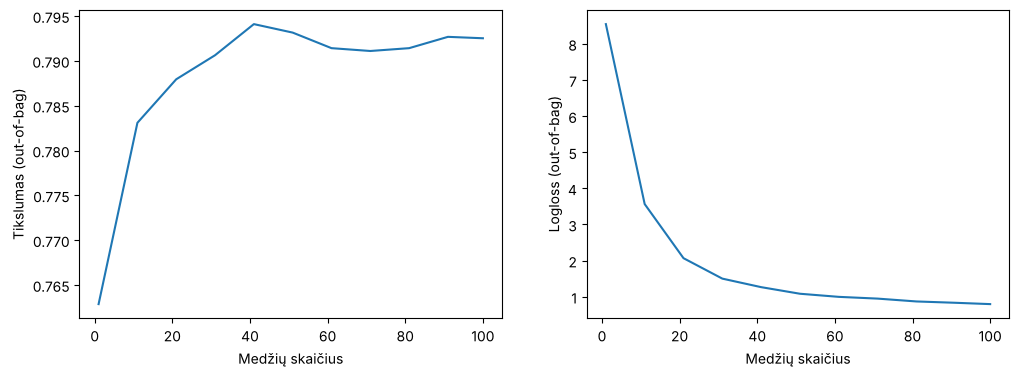

In [12]:
import matplotlib.pyplot as plt

logs = model_1.training_logs()

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot([log.iteration for log in logs], [log.evaluation.accuracy for log in logs])
plt.xlabel('Medžių skaičius')
plt.ylabel('Tikslumas (out-of-bag)')

plt.subplot(1, 2, 2)
plt.plot([log.iteration for log in logs], [log.evaluation.loss for log in logs])
plt.xlabel('Medžių skaičius')
plt.ylabel('Logloss (out-of-bag)')

plt.show()

Tikslumas kyla nuo ~76 % (1 medis) iki ~79 % (40 medžių) ir toliau nebekyla. Nuostolis krenta, nes daugelio medžių
balsavimas duoda nuosaikesnes tikimybes nei vienas medis.

## Kurie požymiai svarbiausi?

`NUM_AS_ROOT`: kiek medžių pirmąjį klausimą užduoda apie šį požymį.

In [13]:
for count, feature in model_1.variable_importances()['NUM_AS_ROOT']:
    print(f'{feature:18} {int(count):3} medžiai(-ių) iš 100')

Contract            44 medžiai(-ių) iš 100
tenure              23 medžiai(-ių) iš 100
InternetService     19 medžiai(-ių) iš 100
PaymentMethod        8 medžiai(-ių) iš 100
MonthlyCharges       4 medžiai(-ių) iš 100
TotalCharges         2 medžiai(-ių) iš 100


Svarbiausi: sutarties tipas (`Contract`), stažas (`tenure`) ir interneto tipas (`InternetService`).

## Vienas miško medis 🌲

`tree_idx=0` yra pirmasis medis, rodomi 3 viršutiniai lygiai. Antrame langelyje tas pats medis tekstu.

In [14]:
model_1.plot_tree(tree_idx=0, max_depth=3)

In [15]:
model_1.print_tree(tree_idx=0, max_depth=3)

'tenure' >= 22.5 [score=0.050064 missing=True]
    ├─(pos)─ 'Contract' in ['Month-to-month'] [score=0.053934 missing=False]
    │        ├─(pos)─ 'InternetService' in ['Fiber optic'] [score=0.029095 missing=False]
    │        │    ...
    │        └─(neg)─ 'MonthlyCharges' >= 90.875 [score=0.014347 missing=False]
    │             ...
    └─(neg)─ 'InternetService' in ['Fiber optic'] [score=0.085709 missing=False]
             ├─(pos)─ 'TotalCharges' >= 120.225 [score=0.019894 missing=True]
             │    ...
             └─(neg)─ 'tenure' >= 5.5 [score=0.039021 missing=True]
                  ...


---
# 5 žingsnis. Prognozavimas su naujais duomenimis 🛠

## Išsaugome 💾

In [16]:
model_1.save('telco_random_forest_100_trees')

## Įkeliame ⚙️

In [17]:
reloaded_model = ydf.load_model('telco_random_forest_100_trees')

Loading model from telco_random_forest_100_trees


## Nauji duomenys 🗃️

* **A**: naujas klientas (2 mėn.), mėnesinė sutartis, šviesolaidis, elektroninis čekis;
* **B**: 4 metų klientas, dvejų metų sutartis, DSL, automatinis pavedimas.

In [18]:
samples = pd.DataFrame([
    {'gender': 'Female', 'SeniorCitizen': 0, 'Partner': 'No', 'Dependents': 'No', 'tenure': 2,
     'PhoneService': 'Yes', 'InternetService': 'Fiber optic', 'Contract': 'Month-to-month',
     'PaperlessBilling': 'Yes', 'PaymentMethod': 'Electronic check',
     'MonthlyCharges': 85.0, 'TotalCharges': 170.0},
    {'gender': 'Male', 'SeniorCitizen': 0, 'Partner': 'Yes', 'Dependents': 'Yes', 'tenure': 48,
     'PhoneService': 'Yes', 'InternetService': 'DSL', 'Contract': 'Two year',
     'PaperlessBilling': 'No', 'PaymentMethod': 'Bank transfer (automatic)',
     'MonthlyCharges': 60.0, 'TotalCharges': 2880.0},
], index=['A', 'B'])
samples

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
A,Female,0,No,No,2,Yes,Fiber optic,Month-to-month,Yes,Electronic check,85.0,170.0
B,Male,0,Yes,Yes,48,Yes,DSL,Two year,No,Bank transfer (automatic),60.0,2880.0


## Prognozuojame 🔮

Naudojame įkeltą modelį.

In [19]:
predictions = reloaded_model.predict(samples)
for name, p in zip(samples.index, predictions):
    print('Tikimybė, kad klientas {} išeis: {:.1f} %'.format(name, 100 * p))

Tikimybė, kad klientas A išeis: 88.0 %
Tikimybė, kad klientas B išeis: 5.0 %


---
# Išvados

| | Rezultatas |
|---|---|
| Testavimo tikslumas | **79,3 %** |
| Bazinis lygis (visada „lieka“) | 75,7 % |
| Atpažinta išėjusių klientų | 81 iš 171 (47 %) |
| Svarbiausi požymiai | `Contract`, `tenure`, `InternetService` |
| Klientas A / B | 88 % / 5 % tikimybė išeiti |

* Modelis lenkia bazinį lygį, bet nedaug: dalis klientų išeina dėl priežasčių, kurių duomenyse nėra.
* Didžiausia rizika: mėnesinė sutartis, mažas stažas, šviesolaidinis internetas.
* Su kitais atsitiktiniais padalijimais tikslumas svyravo nuo 77,6 % iki 80,1 %.